#### A modified version of "AI LSB-ipynb" to test sanitization methods

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import random

import torch
import torch.nn as nn

import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms

seed = 101

np.random.seed(seed)
random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.use_deterministic_algorithms = True
torch.backends.cudnn.benchmark = False

#### Utility methods

In [3]:
def train(net, criterion, optimizer, n_epochs, train_loader, path_model='net.pt'):
    losses = []

    for epoch in range(n_epochs):
        net.train()

        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            x, y = data
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            y_pred = net(x)
            loss = criterion(y_pred, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        losses.append(running_loss / len(train_loader))
        print(f'Epoch {epoch + 1}, Loss: {running_loss / len(train_loader)}')

    torch.save(net.state_dict(), path_model)
    
    plt.plot(range(0, len(losses)), losses)
    plt.title('Training losses')
    plt.show()
    
def test(net, test_loader):
    net.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data in test_loader:
            x, y = data
            x, y = x.to(device), y.to(device)
            y_preds = net(x)
            _, predicted = torch.max(y_preds.data, 1)
            total += y.size(0)
            correct += (predicted == y).sum().item()
            
    return correct, total

In [4]:
def float_to_bin(x):
    # Convert float to binary representation
    return ''.join(f'{byte:08b}' for byte in np.float32(x).tobytes())

def bin_to_float(b):
    # Convert binary representation back to float
    int_bits = int(b, 2)
    return np.frombuffer(int_bits.to_bytes(4, byteorder='big'), dtype=np.float32)[0]

def add_watermark_lsb(net, watermark):
    watermark_bits = ''.join(f'{ord(c):08b}' for c in watermark) # Convert watermark to binary
    watermark_index = 0

    with torch.no_grad():
        for name, param in net.named_parameters():
            if name == 'fc2.weight':
                param_data = param.cpu().numpy()
                for i in np.ndindex(param_data.shape):
                    if watermark_index < len(watermark_bits):
                        original_bin = float_to_bin(param_data[i])
                        new_bin = original_bin[:-1] + watermark_bits[watermark_index]
                        param_data[i] = bin_to_float(new_bin)
                        watermark_index += 1
                param.copy_(torch.tensor(param_data, device=param.device))

                
def extract_watermark(net, watermark_length):
    extracted_bits = ''
    
    with torch.no_grad():
        for name, param in net.named_parameters():
            if name == 'fc2.weight':
                param_data = param.cpu().numpy()
                for i in np.ndindex(param_data.shape):
                    original_bin = float_to_bin(param_data[i])
                    extracted_bits += original_bin[-1]
    watermark_chars = [chr(int(extracted_bits[i:i+8], 2)) for i in range(0, len(extracted_bits), 8)]
    return ''.join(watermark_chars[:watermark_length])

#### Define the neural network

In [5]:
class Net(nn.Module):
    def __init__(self, n_channels=1, h_size=28, w_size=28, last_size=64, hidden_dim=8, n_classes=10):
        super(Net, self).__init__()
        self.n_channels = n_channels
        self.h_size = h_size
        self.w_size = w_size
        self.last_size = last_size
        self.n_classes = n_classes
        self.hidden_dim = hidden_dim
        
        self.embedder = nn.Sequential(
            nn.Conv2d(self.n_channels, self.last_size//2, kernel_size=3, stride=2),
            nn.ReLU(),
            nn.Conv2d(self.last_size//2, self.last_size, kernel_size=3, stride=2),
            nn.ReLU(),
            nn.Conv2d(self.last_size, self.last_size, kernel_size=3, stride=2),
            nn.ReLU()
        )
        
        
        out = self.embedder(torch.rand(1, self.n_channels, self.h_size, self.w_size))
        self.size = out.shape[2]

        self.fc1 = nn.Linear(self.last_size * self.size * self.size, self.last_size)
        self.fc2 = nn.Linear(self.last_size, self.hidden_dim)
        self.out = nn.Linear(self.hidden_dim, self.n_classes)
        
        self.relu = nn.ReLU()
        
        self.init_weights()
        
    def init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(
                    m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.constant_(m.bias, 0)
        
    def forward(self, x):
        x1 = self.embedder(x)
        x1 = x1.view(x1.shape[0], -1)
        
        x2 = self.fc1(x1)
        x2 = self.fc2(self.relu(x2))
        y = self.out(self.relu(x2))
        
        return y

#### Load the data

In [6]:
batch_size = 64
n_epochs = 20

path_model='net.pt'

In [7]:
transform = transforms.Compose([transforms.ToTensor()])

train_set = datasets.MNIST(root='./data', train=True, download=True, transform=transform) 
test_set = datasets.MNIST(root='./data', train=False, download=True, transform=transform) 

train_loader = torch.utils.data.DataLoader(train_set, batch_size = batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size = batch_size)

#### Train the network

In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
net = Net().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)

Epoch 1, Loss: 0.7113531307736313
Epoch 2, Loss: 0.21152954804760687
Epoch 3, Loss: 0.12652899704323506
Epoch 4, Loss: 0.09659993978264902
Epoch 5, Loss: 0.07628113919916724
Epoch 6, Loss: 0.06294026586767246
Epoch 7, Loss: 0.05501288666661932
Epoch 8, Loss: 0.04664652057397646
Epoch 9, Loss: 0.038616492900613156
Epoch 10, Loss: 0.034037809203396725
Epoch 11, Loss: 0.03001565328274947
Epoch 12, Loss: 0.025492795254845397
Epoch 13, Loss: 0.022110027822847444
Epoch 14, Loss: 0.02016655120434137
Epoch 15, Loss: 0.017421756800728477
Epoch 16, Loss: 0.014623625627820713
Epoch 17, Loss: 0.013915104064480882
Epoch 18, Loss: 0.013299900518429409
Epoch 19, Loss: 0.011821258816780755
Epoch 20, Loss: 0.012333892606917146


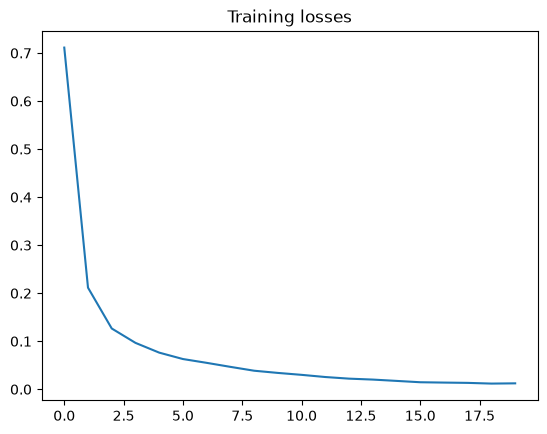

In [9]:
train(net, criterion, optimizer, n_epochs, train_loader, path_model)

#### Load the network and test it 

In [10]:
net.load_state_dict(torch.load(path_model))

<All keys matched successfully>

In [11]:
correct, total = test(net, test_loader)
print(f'Accuracy: {100 * correct / total}%')

Accuracy: 98.75%


#### Embed the watermark

In [12]:
# Now, we want to add a watermark into the fc2 weights
with torch.no_grad():
    for name, param in net.named_parameters():
        if name == 'fc2.weight':
            param_data = param.cpu().numpy()
            print(param_data)

[[ 1.15907220e-02  4.35307831e-01 -8.45720768e-02  4.00702544e-02
  -8.68369415e-02  1.20209455e-01  9.84187499e-02  3.10235828e-01
  -2.26100963e-02 -1.53759019e-02 -1.55618414e-01 -8.29158630e-03
   1.10708168e-02 -1.48155630e-01  1.75544232e-01 -1.56125368e-03
  -9.55724791e-02  3.76959562e-01 -3.22519452e-03  2.43042454e-01
  -1.24175278e-02  7.73259029e-02 -1.89442746e-02  7.78452754e-02
   1.45177217e-02  1.12024602e-02 -3.47119663e-03  2.65089899e-01
  -1.30214155e-01  2.76584059e-01  1.57505095e-01 -5.70174269e-02
  -2.54250504e-03  7.92314205e-03  1.17243803e-03  1.96495056e-02
   1.23071678e-01  1.98377803e-01  3.76539566e-02 -9.62339118e-02
   4.01778638e-01  7.77153485e-03  1.73561666e-02 -1.30947791e-02
   1.19186372e-01 -2.06335485e-02 -3.12064961e-02  9.82811525e-02
  -2.22912561e-02  7.74647221e-02 -2.61410117e-01 -9.26341936e-02
   9.41700786e-02  1.62954768e-03  1.13324627e-01  2.33051628e-02
   1.88260898e-02 -2.73805737e-01 -2.13602588e-01 -1.37182130e-02
   1.49145

In [13]:
watermark = "AI4SS"
add_watermark_lsb(net, watermark)

In [14]:
# Check
with torch.no_grad():
    for name, param in net.named_parameters():
        if name == 'fc2.weight':
            param_data = param.cpu().numpy()
            print(param_data)

[[ 1.15907220e-02  1.74123132e+00 -2.11430192e-02  1.00175636e-02
  -2.17092354e-02  3.00523639e-02  2.46046875e-02  1.24094331e+00
  -2.26100963e-02 -6.15036078e-02 -1.55618414e-01 -8.29158630e-03
   4.42832671e-02 -1.48155630e-01  1.75544232e-01 -6.24501472e-03
  -2.38931198e-02  3.76959562e-01 -3.22519452e-03  9.72169816e-01
  -1.24175278e-02  7.73259029e-02 -1.89442746e-02  1.94613189e-02
   1.45177217e-02  4.48098406e-02 -8.67799157e-04  1.06035960e+00
  -1.30214155e-01  2.76584059e-01  6.30020380e-01 -5.70174269e-02
  -6.35626260e-04  3.16925682e-02  1.17243803e-03  7.85980225e-02
   3.07679195e-02  1.98377803e-01  3.76539566e-02 -9.62339118e-02
   4.01778638e-01  7.77153485e-03  1.73561666e-02 -1.30947791e-02
   1.19186372e-01 -2.06335485e-02 -3.12064961e-02  9.82811525e-02
  -2.22912561e-02  7.74647221e-02 -2.61410117e-01 -9.26341936e-02
   9.41700786e-02  1.62954768e-03  1.13324627e-01  2.33051628e-02
   1.88260898e-02 -2.73805737e-01 -2.13602588e-01 -1.37182130e-02
   1.49145

In [15]:
correct, total = test(net, test_loader)
print(f'Accuracy: {100 * correct / total}%')

Accuracy: 92.88%


In [16]:
extracted_watermark = extract_watermark(net, len(watermark))
print(f'Extracted watermark: {extracted_watermark}')

Extracted watermark: AI4SS


#### Sanitization Part

In [17]:
import copy
import torch
import torch.nn as nn


def watermark_to_bits(text: str) -> str:
    return ''.join(f'{ord(c):08b}' for c in text)


def bit_error_rate(expected_text: str, extracted_text: str) -> float:
    
    exp_bits = watermark_to_bits(expected_text)
    ext_bits = watermark_to_bits(extracted_text)
    if len(exp_bits) == 0:
        return 1.0

    min_len = min(len(exp_bits), len(ext_bits))
    errors = sum(1 for a, b in zip(exp_bits[:min_len], ext_bits[:min_len]) if a != b)
    errors += abs(len(exp_bits) - len(ext_bits))
    return errors / len(exp_bits)


def extract_real_lsb_bits(net, n_bits: int, param_name: str = 'fc2.weight', bit_pos: int = 0) -> str:
    
    bits_out = []
    with torch.no_grad():
        for name, param in net.named_parameters():
            if name == param_name:
                w_int = param.detach().cpu().view(torch.int32).flatten()
                for val in w_int:
                    if len(bits_out) >= n_bits:
                        break
                    bits_out.append(str((int(val.item()) >> bit_pos) & 1))
                break
    return ''.join(bits_out)


def sanitize_flp_k(base_net, device, k_bits: int = 10, only_target_layer: bool = True, target_param_name: str = 'fc2.weight'):
    
    assert 1 <= k_bits <= 23, "k_bits must be between 1 and 23 for IEEE-754 float32."

    sanitized_net = copy.deepcopy(base_net).to(device)
    lower_mask = (1 << k_bits) - 1
    keep_mask = int(0xFFFFFFFF ^ lower_mask)

    with torch.no_grad():
        for name, param in sanitized_net.named_parameters():
            if 'weight' not in name:
                continue
            if only_target_layer and name != target_param_name:
                continue

            w_int = param.data.view(torch.int32)
            rand_low = torch.randint(
                low=0,
                high=(1 << k_bits),
                size=w_int.shape,
                device=w_int.device,
                dtype=torch.int32,
            )
            new_int = (w_int & keep_mask) | rand_low
            param.data.copy_(new_int.view(torch.float32))

    return sanitized_net


def sanitize_qint8(base_net, device, only_target_layer: bool = True, target_param_name: str = 'fc2.weight', per_channel: bool = False):
    
    sanitized_net = copy.deepcopy(base_net).to(device)

    with torch.no_grad():
        for name, param in sanitized_net.named_parameters():
            if 'weight' not in name:
                continue
            if only_target_layer and name != target_param_name:
                continue

            w = param.data
            if per_channel and w.ndim >= 2:
                dims = tuple(range(1, w.ndim))
                max_abs = w.abs().amax(dim=dims, keepdim=True)
            else:
                max_abs = w.abs().max()

            scale = torch.clamp(max_abs / 127.0, min=1e-8)
            q = torch.clamp(torch.round(w / scale), -128, 127).to(torch.int8)
            param.data.copy_(q.to(torch.float32) * scale)

    return sanitized_net

In [18]:
n_lsb_bits = len(watermark) * 8
lsb_ref = extract_real_lsb_bits(net, n_lsb_bits, param_name='fc2.weight', bit_pos=0)

variants = [
    ("Watermarked (Baseline)", copy.deepcopy(net).to(device)),
    ("FLP 10 (all weights)", sanitize_flp_k(net, device, k_bits=10, only_target_layer=False)),
    ("FLP 23 (all weights)", sanitize_flp_k(net, device, k_bits=23, only_target_layer=False)),
    ("Qint8 (all weights)", sanitize_qint8(net, device, only_target_layer=False)),
]

print(f"{'Method':<26} | {'Acc (%)':>8} | {'Text BER':>8} | {'LSB-0 BER':>9} | {'Extracted'}")
print("-" * 86)

for label, m_var in variants:
    c, t = test(m_var, test_loader)
    acc = 100.0 * c / t
    ext = extract_watermark(m_var, len(watermark))
    t_ber = bit_error_rate(watermark, ext)

    lsb_cur = extract_real_lsb_bits(m_var, n_lsb_bits, param_name='fc2.weight', bit_pos=0)
    lsb_ber = sum(1 for a, b in zip(lsb_ref, lsb_cur) if a != b) / n_lsb_bits

    print(f"{label:<26} | {acc:7.2f}% | {t_ber:8.2f} | {lsb_ber:9.2f} | {repr(ext)}")

Method                     |  Acc (%) | Text BER | LSB-0 BER | Extracted
--------------------------------------------------------------------------------------
Watermarked (Baseline)     |   92.88% |     0.00 |      0.00 | 'AI4SS'
FLP 10 (all weights)       |   92.88% |     0.00 |      0.60 | 'AI4SS'
FLP 23 (all weights)       |   80.61% |     0.00 |      0.57 | 'AI4SS'
Qint8 (all weights)        |   92.60% |     0.10 |      0.30 | 'AH\x14[\x13'
